# Commodity Price Forecasting AI Agent
## Notebook 04 - ARIMA Forecasting Model

### Objective
This notebook develops an ARIMA (AutoRegressive Integrated Moving Average) model to forecast silver closing prices. The model is trained on historical price data and evaluated using standard forecasting metrics.

**Project:** Zetheta Project 1D

**Author:** Sanjivanee Sathe

**Date:** July 2026

In [2]:
# =====================================================
# Import Libraries
# =====================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

from statsmodels.tsa.arima.model import ARIMA

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# =====================================================
# Load Dataset
# =====================================================

silver = pd.read_csv(
    "../outputs/feature_engineered_silver.csv",
    parse_dates=["Date"]
)

silver.head()

,Date,Open,High,Low,Close,Adj_Close,Volume,VWAP,Returns_Pct,Log_Returns,...,Open_Close_Range,EMA_7,EMA_14,EMA_30,RSI_14,MACD,MACD_Signal,BB_Middle,BB_Upper,BB_Lower
0,2000-02-14,5.3331,5.3487,5.3321,5.3336,5.3336,36878,5.3382,-0.3622,-0.003628,...,-0.0005,5.330154,5.314042,5.286113,47.688518,0.026011,0.023204,5.304540,5.417420,5.191660
1,2000-02-15,5.3607,5.3662,5.3607,5.3608,5.3608,23437,5.3626,0.5102,0.005089,...,-0.0001,5.337816,5.320276,5.290931,50.009053,0.027479,0.024059,5.306630,5.422154,5.191106
2,2000-02-16,5.3526,5.4488,5.3185,5.3539,5.3539,38455,5.3737,-0.1296,-0.001297,...,-0.0013,5.341837,5.324760,5.294994,68.792030,0.027766,0.024800,5.306575,5.422003,5.191147
3,2000-02-17,5.3307,5.4092,5.2876,5.3405,5.3405,19680,5.3458,-0.2504,-0.002507,...,-0.0098,5.341503,5.326858,5.297930,66.602363,0.026605,0.025161,5.307905,5.424297,5.191513
4,2000-02-18,5.2893,5.2949,5.2893,5.2896,5.2896,24962,5.2913,-0.9527,-0.009573,...,-0.0003,5.328527,5.321890,5.297392,58.790252,0.021332,0.024395,5.308670,5.424331,5.193009


In [4]:
# =====================================================
# Prepare Time Series
# =====================================================

silver = silver.sort_values("Date")

silver.set_index("Date", inplace=True)

price = silver["Close"]

print(price.head())

Date
2000-02-14    5.3336
2000-02-15    5.3608
2000-02-16    5.3539
2000-02-17    5.3405
2000-02-18    5.2896
Name: Close, dtype: float64


In [5]:
# =====================================================
# Train-Test Split
# =====================================================

train_size = int(len(price) * 0.80)

train = price[:train_size]

test = price[train_size:]

print("Training Samples :", len(train))
print("Testing Samples  :", len(test))

Training Samples : 5402
Testing Samples  : 1351


In [6]:
# =====================================================
# Train ARIMA Model
# =====================================================

model = ARIMA(train, order=(5,1,0))

arima_model = model.fit()

print(arima_model.summary())

                               SARIMAX Results                                
Dep. Variable:                  Close   No. Observations:                 5402
Model:                 ARIMA(5, 1, 0)   Log Likelihood               -2030.934
Date:                Sat, 18 Jul 2026   AIC                           4073.868
Time:                        16:59:39   BIC                           4113.434
Sample:                    02-14-2000   HQIC                          4087.681
                         - 10-27-2020                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0106      0.008      1.357      0.175      -0.005       0.026
ar.L2          0.0081      0.007      1.086      0.278      -0.006       0.023
ar.L3         -0.0166      0.008     -2.168      0.0

In [7]:
# =====================================================
# Forecast
# =====================================================

forecast = arima_model.forecast(steps=len(test))

forecast = pd.Series(
    forecast,
    index=test.index
)

forecast.head()

Date
2020-10-28    24.283245
2020-10-29    24.267704
2020-10-30    24.269070
2020-11-02    24.274971
2020-11-03    24.271703
Name: predicted_mean, dtype: float64

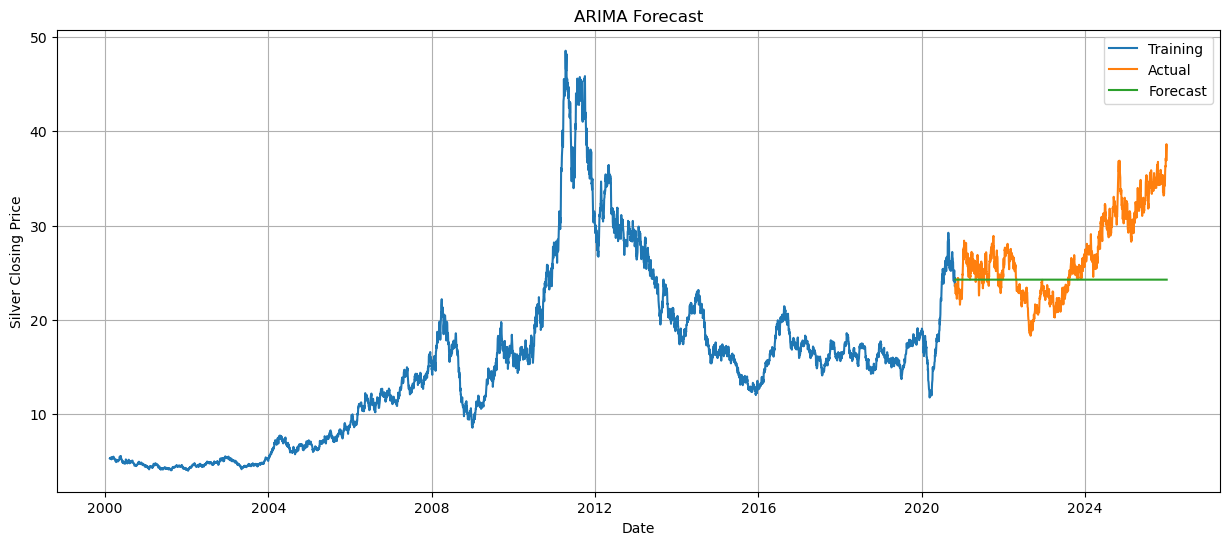

In [8]:
# =====================================================
# Plot Forecast
# =====================================================

plt.figure(figsize=(15,6))

plt.plot(train.index, train, label="Training")

plt.plot(test.index, test, label="Actual")

plt.plot(forecast.index, forecast, label="Forecast")

plt.title("ARIMA Forecast")

plt.xlabel("Date")

plt.ylabel("Silver Closing Price")

plt.legend()

plt.grid(True)

plt.show()

In [9]:
# =====================================================
# Model Evaluation
# =====================================================

mae = mean_absolute_error(test, forecast)

rmse = np.sqrt(mean_squared_error(test, forecast))

mape = np.mean(np.abs((test - forecast) / test)) * 100

print(f"MAE  : {mae:.4f}")

print(f"RMSE : {rmse:.4f}")

print(f"MAPE : {mape:.2f}%")

MAE  : 3.9266
RMSE : 5.1345
MAPE : 13.45%


In [10]:
# =====================================================
# Save Predictions
# =====================================================

results = pd.DataFrame({
    "Actual": test,
    "Predicted": forecast
})

results.to_csv("../outputs/arima_predictions.csv")

print("ARIMA predictions saved successfully.")

ARIMA predictions saved successfully.


# Conclusion

The ARIMA model was trained using historical silver closing prices and evaluated using MAE, RMSE, and MAPE. The forecasted values have been exported for comparison with other forecasting models in subsequent notebooks.